In [194]:
import networkx as nx

In [195]:
G = nx.Graph()

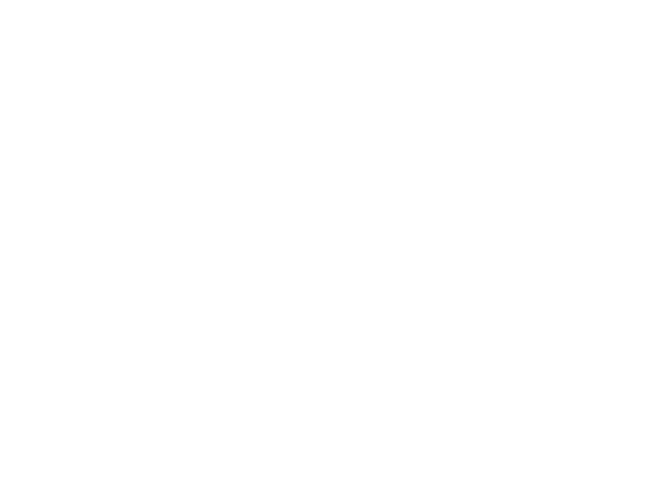

In [196]:
nx.draw(G)

In [197]:
G.add_node(1)

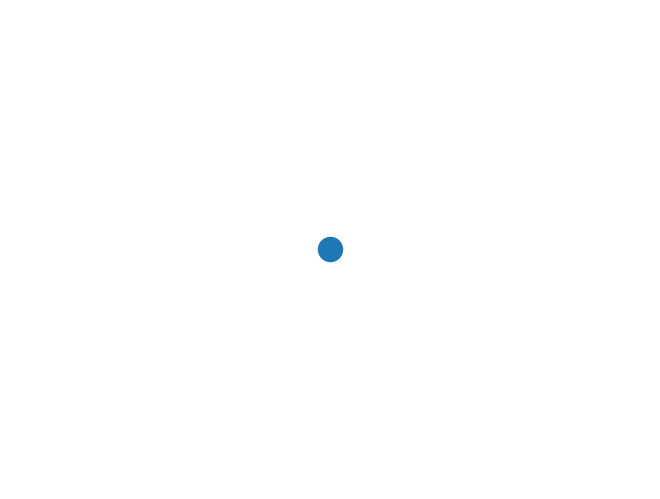

In [198]:
nx.draw(G)

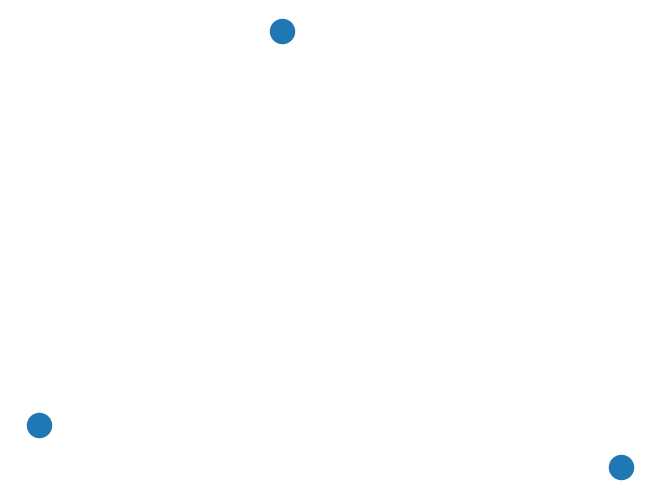

In [199]:
G.add_nodes_from([2, 3])
nx.draw(G)

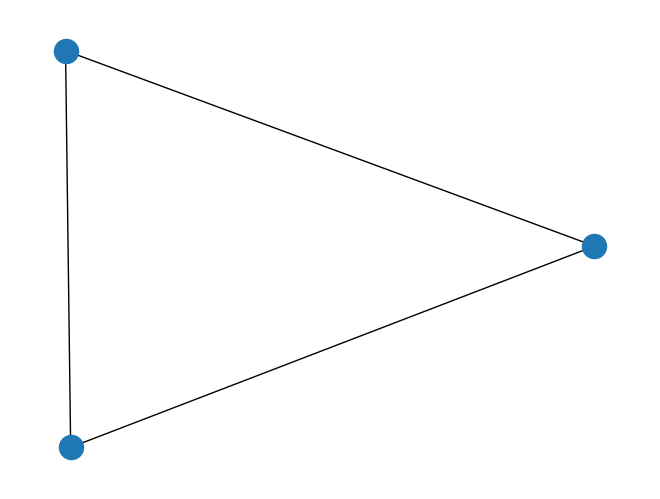

In [200]:
G.add_edges_from([[1,2], [2,3], [3, 1]])
nx.draw(G)

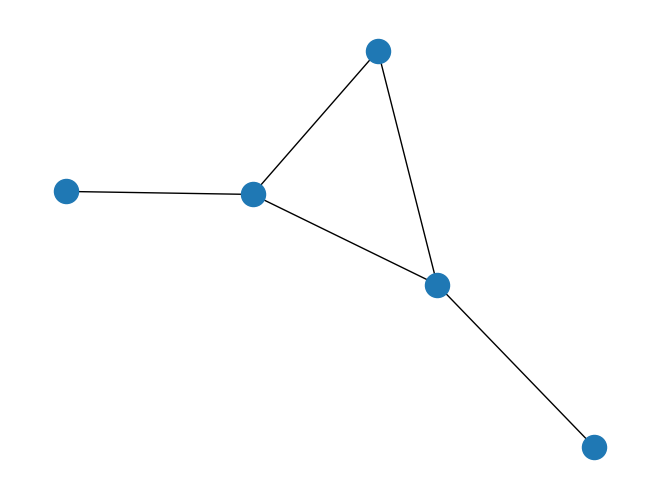

In [201]:
G.add_nodes_from([4, 5])
G.add_edges_from([[3,5], [2, 4]])
nx.draw(G)

In [202]:
print(f"Number of Nodes: {G.number_of_nodes()}")

Number of Nodes: 5


In [203]:
print(f"Number of Edges: {G.number_of_edges()}")

Number of Edges: 5


In [204]:
print(f"Graph Nodes: {G.nodes}")
print(f"Graph Edges: {G.edges}")

Graph Nodes: [1, 2, 3, 4, 5]
Graph Edges: [(1, 2), (1, 3), (2, 3), (2, 4), (3, 5)]


In [205]:
print(f"Graph Graphs: {G.graph}")

Graph Graphs: {}


In [206]:
G.add_nodes_from([21, 22, 20])
G.add_edges_from([[21, 1], [22, 5], [20, 4]])

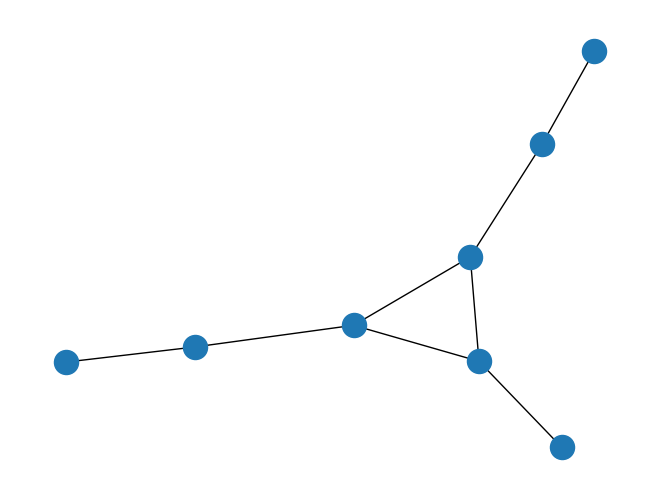

In [207]:
nx.draw(G)


In [208]:
from networkx.readwrite import json_graph
# readwrite contains functionality for reading and writing graph data in different formats.
# json_graph - json_graph provides functions to convert graphs into JSON-compatible data structures and vice versa.


json_data = json_graph.node_link_data(G)
# node_link_data(): Converts a graph into a dictionary containing information about its nodes and edges.

json_data

{'directed': False,
 'multigraph': False,
 'graph': {},
 'nodes': [{'id': 1},
  {'id': 2},
  {'id': 3},
  {'id': 4},
  {'id': 5},
  {'id': 21},
  {'id': 22},
  {'id': 20}],
 'edges': [{'source': 1, 'target': 2},
  {'source': 1, 'target': 3},
  {'source': 1, 'target': 21},
  {'source': 2, 'target': 3},
  {'source': 2, 'target': 4},
  {'source': 3, 'target': 5},
  {'source': 4, 'target': 20},
  {'source': 5, 'target': 22}]}

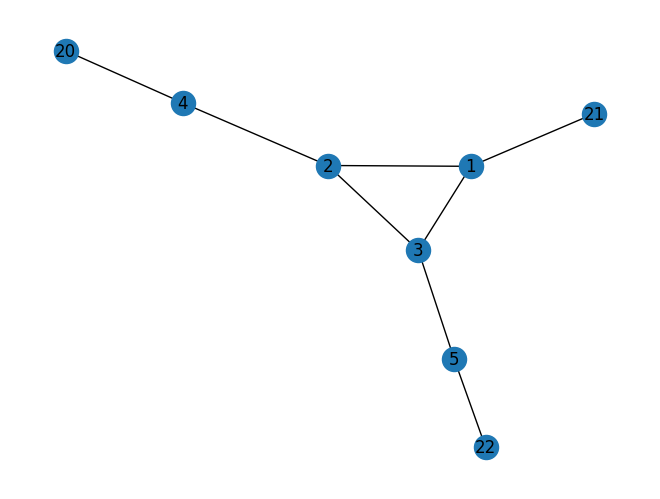

In [209]:
json_data_to_graph = json_graph.node_link_graph(json_data)

# node_link_graph(): Converts node-link data (dictionary) back into a NetworkX graph.

nx.draw(json_data_to_graph, with_labels=True)

In [210]:
G.remove_nodes_from([2,3])

# remove_nodes_from(): NetworkX method for removing multiple nodes
# [2, 3]: List of node IDs to remove.

json_data1 = json_graph.node_link_data(G)
# node_link_data(): Converts a graph into a dictionary containing information about its nodes and edges.

json_data1

# nx.draw(G, with_labels=True)
# G.remove_node(2)          # Remove one node
# G.remove_nodes_from([2,3]) # Remove multiple nodes

{'directed': False,
 'multigraph': False,
 'graph': {},
 'nodes': [{'id': 1},
  {'id': 4},
  {'id': 5},
  {'id': 21},
  {'id': 22},
  {'id': 20}],
 'edges': [{'source': 1, 'target': 21},
  {'source': 4, 'target': 20},
  {'source': 5, 'target': 22}]}

In [211]:
G.is_directed()

False

In [212]:
G.is_multigraph()

False

## Neighbour and Adjacency

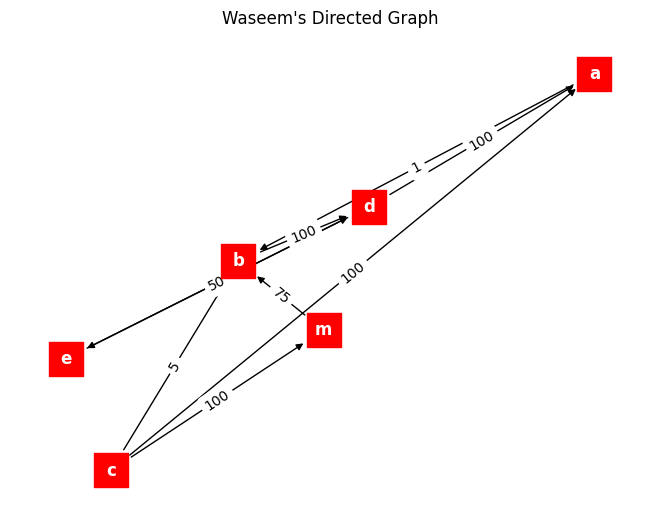

Graph Data: {'name': "Waseem's Directed Graph", 'description': 'A simple directed graph', 'created_by': 'Paxto'}
Order of Graph: 6
Number of Nodes: 6
Number of Edges: 9
Graph Edges: [('a', 'b'), ('b', 'd'), ('c', 'b'), ('c', 'm'), ('c', 'a'), ('e', 'd'), ('d', 'e'), ('d', 'a'), ('m', 'b')]
Graph Nodes: ['a', 'b', 'c', 'e', 'd', 'm']


In [213]:
import networkx as nx
import matplotlib.pyplot as plt

Graph = nx.DiGraph()
Graph.add_edges_from([
    ("a", "b", {"weight": 1}),
    ("c", "b", {"weight": 5}),
    ("e", "d", {"weight": 25}),
    ("d", "e", {"weight": 50}),
    ("m", "b", {"weight": 75}),
    ("d", "a", {"weight": 100}),
    ("c", "m", {"weight": 100}),
    ("c", "a", {"weight": 100}),
    ("b", "d", {"weight": 100}),
])

Graph.graph["name"] = "Waseem's Directed Graph"
Graph.graph["description"] = "A simple directed graph"
Graph.graph["created_by"] = "Paxto"

# 1. Generate node positions first so nodes and edge labels align
pos = nx.spring_layout(Graph, seed=42)

# 2. Use node_shape="s" for square and curve arrows so ("e","d") and ("d","e") don't overlap
nx.draw(
    Graph,
    pos,
    with_labels=True,
    node_color="red",
    node_size=600,
    node_shape="s",
    font_color="white",
    font_weight="bold",
    # connectionstyle="arc3,rad=0.1"
)

# 3. Extract and draw the edge weights
edge_weights = nx.get_edge_attributes(Graph, "weight")
nx.draw_networkx_edge_labels(Graph, pos, edge_labels=edge_weights)

plt.title(Graph.graph["name"])
plt.show()

print(f"Graph Data: {Graph.graph}")
print(f"Order of Graph: {Graph.order()}")
print(f"Number of Nodes: {Graph.number_of_nodes()}")
print(f"Number of Edges: {Graph.number_of_edges()}")
print(f"Graph Edges: {Graph.edges}")
print(f"Graph Nodes: {Graph.nodes}")

In [214]:
print([n for n in Graph.neighbors("c")])

['b', 'm', 'a']


In [215]:
for node in Graph.nodes():
  print(node, list(Graph.neighbors(node)))

a ['b']
b ['d']
c ['b', 'm', 'a']
e ['d']
d ['e', 'a']
m ['b']


In [216]:
for x in Graph.nodes:
  print('Neighbors for ' + x + ':', [n for n in Graph.neighbors(x)], "\n")

Neighbors for a: ['b'] 

Neighbors for b: ['d'] 

Neighbors for c: ['b', 'm', 'a'] 

Neighbors for e: ['d'] 

Neighbors for d: ['e', 'a'] 

Neighbors for m: ['b'] 



In [217]:
print(list(Graph.neighbors('d')))
print(list(Graph.predecessors('d')))
print(Graph.in_degree('d'))
print(Graph.out_degree('d'))

['e', 'a']
['e', 'b']
2
2


In [218]:
A = nx.adjacency_matrix(Graph)
print(A.todense())

[[  0   1   0   0   0   0]
 [  0   0   0   0 100   0]
 [100   5   0   0   0 100]
 [  0   0   0   0  25   0]
 [100   0   0  50   0   0]
 [  0  75   0   0   0   0]]


In [219]:
A.diagonal()

array([0, 0, 0, 0, 0, 0])

In [220]:
A_dense = A.setdiag(A.diagonal() + 2)
print(A.todense())


[[  2   1   0   0   0   0]
 [  0   2   0   0 100   0]
 [100   5   2   0   0 100]
 [  0   0   0   2  25   0]
 [100   0   0  50   2   0]
 [  0  75   0   0   0   2]]


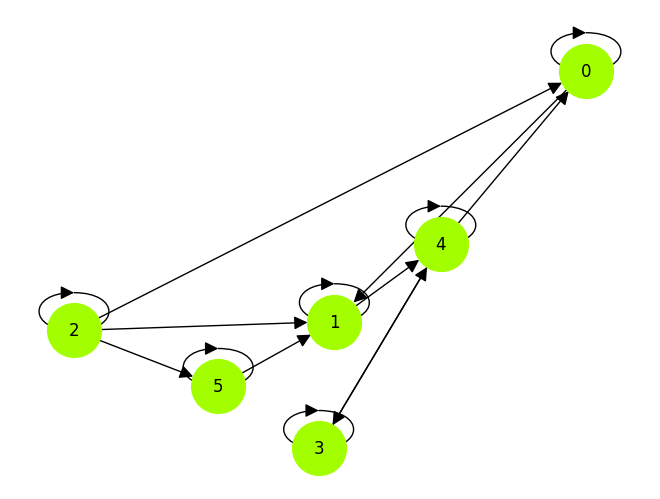

In [221]:
A_dense = A.toarray()
Graph2 = nx.from_numpy_array(
    A_dense,
    create_using=nx.DiGraph()
)
nx.draw(
    Graph2,
    with_labels=True,
    node_color="#A3FF00",
    node_size=1500,
    arrows=True,
    arrowsize=20
)

plt.show()

[(0, 1, 0), (1, 0, 0), (2, 2, 0), (2, 2, 1)]
[0, 1, 2]


array([[0., 2., 0.],
       [1., 0., 0.],
       [0., 0., 4.]])

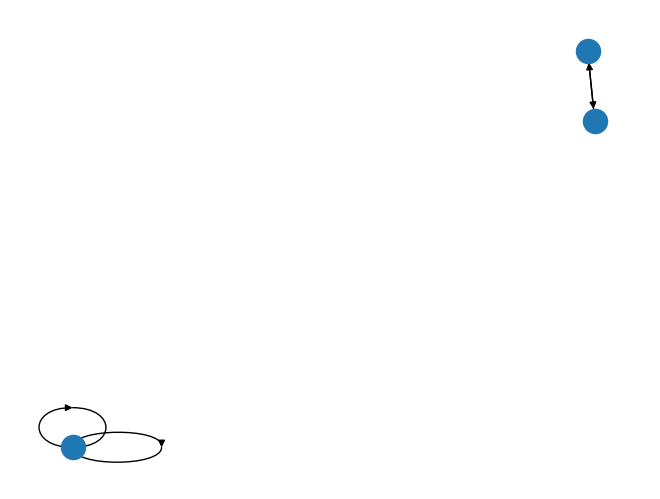

In [222]:
MultiG = nx.MultiDiGraph()
MultiG.add_edge(0, 1, weight=2)
MultiG.add_edge(1, 0)
MultiG.add_edge(2, 2, weight=3)
MultiG.add_edge(2, 2)
nx.draw(MultiG)
print(MultiG.edges)
print(MultiG.nodes)
nx.to_numpy_array(MultiG, nodelist=[0, 1, 2])